<a href="https://www.kaggle.com/code/gowthamsevathan/netflix-prize-data?scriptVersionId=375096103" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Netflix Prize: Predicting Movie Ratings

## Business Problem
Given a customer's past ratings, can we predict the rating they will give a movie they have not seen yet? This is a **recommendation system** problem.

## Data
- 100 million ratings, ~480K customers, 17,770 movies (1998 to 2005)
- Files: `combined_data_1-4.txt`, `movie_titles.csv`, `probe.txt`, `qualifying.txt`

## Success Metric
**RMSE** (root mean squared error). Lower is better.

## Roadmap
1. Setup and load data
2. Validate the load (data quality checks)
3. Exploratory data analysis (EDA)
4. Baseline model
5. Matrix factorization model
6. Evaluation

##  Libraries

In [31]:
import os                      
import gc                      
import warnings                

import numpy as np             
import pandas as pd            
import matplotlib.pyplot as plt  
import seaborn as sns
import torch                   
import psutil 
import time  

## Settings

In [2]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.4f}'.format)  # 4 decimals, thousands commas
sns.set_theme(style='whitegrid')

##  Paths

In [3]:
BASE = '/kaggle/input/datasets/netflix-inc/netflix-prize-data/'

print('Setup done')
print('pandas', pd.__version__, '| numpy', np.__version__)

Setup done
pandas 2.3.3 | numpy 2.1.3


## 1. Setup

**Goal:** Put all imports, settings and paths in one place, so the notebook has a single place to check its dependencies.

- Libraries: `pandas`, `numpy` for data, `matplotlib`, `seaborn` for charts
- `gc` lets us free memory, since the data is large (100M rows)
- `BASE` stores the data folder path once, so we never retype it

Modeling libraries will be added here later, when we reach the modeling phase.

In [4]:
def load_netflix(n):
    """Read combined_data_n.txt and return a tidy table."""
    # 1. read as plain text
    raw = pd.read_csv(BASE + f'combined_data_{n}.txt', header=None,
                      names=['customer_id', 'rating', 'date'], dtype=str)

    # 2. find movie lines (they have no rating) and read their IDs
    is_movie = raw['rating'].isna().to_numpy()
    pos = np.flatnonzero(is_movie)                               # row numbers of movie lines
    movie_ids = raw['customer_id'].iloc[pos].str[:-1].astype('int16').to_numpy()  # "1:" -> 1

    # 3. repeat each movie ID for all its rating rows
    counts = np.diff(np.append(pos, len(raw)))                   # block sizes
    raw['movie_id'] = np.repeat(movie_ids, counts)

    # 4. drop movie lines, convert to small types
    raw = raw[~is_movie]
    out = pd.DataFrame({
        'movie_id':    raw['movie_id'].to_numpy(),
        'customer_id': raw['customer_id'].astype('int32').to_numpy(),
        'rating':      raw['rating'].astype('int8').to_numpy(),
        'date':        pd.to_datetime(raw['date'], format='%Y-%m-%d'),
    })
    del raw
    gc.collect()
    return out

df1 = load_netflix(1); print('df1', df1.shape)
df2 = load_netflix(2); print('df2', df2.shape)
df3 = load_netflix(3); print('df3', df3.shape)
df4 = load_netflix(4); print('df4', df4.shape)

df1 (24053764, 4)
df2 (26977591, 4)
df3 (22601629, 4)
df4 (26847523, 4)


## 2. Load the Ratings

**Problem:** Each file mixes two kinds of lines: a movie line (`1:`) and rating lines (`customer_id, rating, date`). The movie ID is not a column, so we must copy it down onto every rating beneath it.

**Approach:** A *vectorized* method, not a slow line-by-line loop:
1. Read the file as plain text
2. Find the movie lines (they have no rating) and read their IDs
3. Repeat each ID for all of its rating rows
4. Drop the movie lines and convert columns to small data types

**Memory saving:** Smallest type that fits each column

| Column | Type | Why |
|---|---|---|
| `movie_id` | int16 | max 17,770 |
| `customer_id` | int32 | max ~2.6M |
| `rating` | int8 | values 1 to 5 |
| `date` | datetime64 | real dates |

**Result:** four tables, `df1` to `df4`, one per file.

**Check:** the four row counts should add up to **100,480,507**.

## 3. Data Quality Checks

**Goal:** Prove the loaded data is complete and sane before analysing it.

| # | Check | Expected |
|---|---|---|
| 1 | Total rows | 100,480,507 |
| 2 | Missing values | 0 |
| 3 | Value ranges | Ratings 1 to 5, dates 1998 to 2005, movie IDs 1 to 17,770 |
| 4 | Memory usage | About 1.5 GB total |

 Bad data in gives bad conclusions out. These checks are cheap and catch loading mistakes early.

In [5]:
dfs = {'df1': df1, 'df2': df2, 'df3': df3, 'df4': df4}

# Check 1: total rows
total = sum(len(d) for d in dfs.values())
print('CHECK 1 | total rows:', f'{total:,}', '->'  if total == 100_480_507 else 'MISMATCH')

# Check 2: missing values
print('\nCHECK 2 | missing values')
for name, d in dfs.items():
    print(' ', name, int(d.isna().sum().sum()))

# Check 3: value ranges
print('\nCHECK 3 | ranges')
for name, d in dfs.items():
    print(' ', name,
          '| movie', d['movie_id'].min(), '-', d['movie_id'].max(),
          '| rating', d['rating'].min(), '-', d['rating'].max(),
          '| date', d['date'].min().date(), 'to', d['date'].max().date())

# Check 4: memory
print('\nCHECK 4 | memory (GB)')
for name, d in dfs.items():
    print(' ', name, round(d.memory_usage(deep=True).sum() / 1e9, 2))

CHECK 1 | total rows: 100,480,507 ->

CHECK 2 | missing values
  df1 0
  df2 0
  df3 0
  df4 0

CHECK 3 | ranges
  df1 | movie 1 - 4499 | rating 1 - 5 | date 1999-11-11 to 2005-12-31
  df2 | movie 4500 - 9210 | rating 1 - 5 | date 1999-11-11 to 2005-12-31
  df3 | movie 9211 - 13367 | rating 1 - 5 | date 1999-11-11 to 2005-12-31
  df4 | movie 13368 - 17770 | rating 1 - 5 | date 1999-11-11 to 2005-12-31

CHECK 4 | memory (GB)
  df1 0.55
  df2 0.62
  df3 0.52
  df4 0.62


### 3b.  Fixing the Row Index

**Observation:** Tables used 23 bytes per row, but the column types add up to only 15.

**Hypothesis:** The loader kept the old row labels from the raw file as an 8-byte-per-row index.

**Test and fix:** Check the index type. If it is not a `RangeIndex`, reset it (the data itself does not change).

**Expected result:** about 1.5 GB total instead of 2.3 GB.

In [6]:
for name, d in dfs.items():
    print(name, 'index before:', type(d.index).__name__)
    if not isinstance(d.index, pd.RangeIndex):
        d.reset_index(drop=True, inplace=True)
    print(name, 'index after: ', type(d.index).__name__,
          '| memory GB:', round(d.memory_usage(deep=True).sum() / 1e9, 2))
gc.collect()

df1 index before: Index
df1 index after:  RangeIndex | memory GB: 0.36
df2 index before: Index
df2 index after:  RangeIndex | memory GB: 0.4
df3 index before: Index
df3 index after:  RangeIndex | memory GB: 0.34
df4 index before: Index
df4 index after:  RangeIndex | memory GB: 0.4


0

## 4. EDA

###  Rating Distribution

**Question:** How are the 100M ratings spread across 1 to 5 stars?

**Approach:** Count ratings inside each of the four tables and add the tallies, instead of merging 100M rows (saves memory). Show counts and percentages, and compute the overall mean.

**Why it matters:** The overall mean is the simplest possible prediction, and it will be our first baseline.

           count  percent
rating                   
1        4617990   4.5959
2       10132080  10.0836
3       28811247  28.6735
4       33750958  33.5896
5       23168232  23.0574

Global mean rating: 3.6043


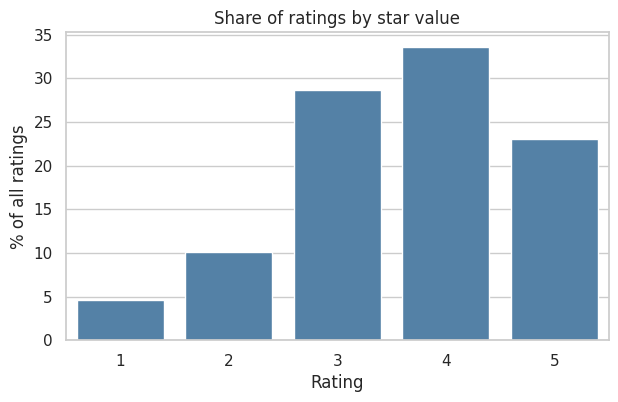

In [7]:
# count ratings in each table, then add the four tallies together
rating_counts = sum(d['rating'].value_counts() for d in dfs.values()).sort_index()

summary = pd.DataFrame({
    'count': rating_counts,
    'percent': rating_counts / rating_counts.sum() * 100
})
print(summary)

# overall mean = sum(rating x count) / total count
global_mean = (rating_counts.index * rating_counts).sum() / rating_counts.sum()
print('\nGlobal mean rating:', round(float(global_mean), 4))

# chart
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=summary.index, y=summary['percent'], ax=ax, color='steelblue')
ax.set_title('Share of ratings by star value')
ax.set_xlabel('Rating')
ax.set_ylabel('% of all ratings')
plt.show()

**Findings (4.1):**
- 4 stars is the most common rating (33.6%), then 3 (28.7%) and 5 (23.1%). 1 star is rarest (4.6%).
- Global mean is **3.6043**, below the most common value because the distribution is left-skewed.
- 85% of ratings are 3 or higher: users mostly rate movies they chose to watch (selection bias).
- Decision: first baseline predicts 3.6043; evaluate with RMSE.

### 4.2 Ratings Per Movie

**Question:** Do all movies get a similar number of ratings, or do a few dominate?

**Approach:** Movie IDs do not overlap between the four files, so group by movie inside each table and stack the four small results. This avoids merging 100M rows.

**Why it matters:** A movie's average is only trustworthy if it has enough ratings. This tells us how many movies are "thin".

**Chart:** Log-scale x-axis, because counts span several orders of magnitude.

shape: (17770, 2)
total ratings: 100,480,507
count    17,770.0000
mean      5,654.5024
std      16,909.6733
min           3.0000
10%         117.0000
25%         192.0000
50%         561.0000
75%       2,667.7500
90%      12,303.8000
99%      97,128.4300
max     232,944.0000
Name: count, dtype: float64

Top 10% of movies hold 76.6% of all ratings


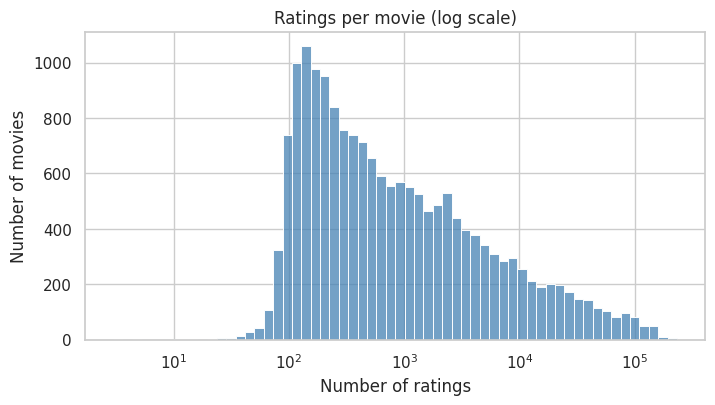

In [8]:
movie_stats = pd.concat(
    [d.groupby('movie_id')['rating'].agg(['count', 'mean']) for d in dfs.values()]
)

print('shape:', movie_stats.shape)
print('total ratings:', f"{int(movie_stats['count'].sum()):,}")
print(movie_stats['count'].describe(percentiles=[.1, .25, .5, .75, .9, .99]))

# share of all ratings held by the top 10% most-rated movies
sorted_counts = movie_stats['count'].sort_values(ascending=False)
top10_share = sorted_counts.iloc[:len(sorted_counts) // 10].sum() / sorted_counts.sum()
print(f"\nTop 10% of movies hold {top10_share:.1%} of all ratings")

# chart
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(movie_stats['count'], bins=60, log_scale=True, ax=ax, color='steelblue')
ax.set_title('Ratings per movie (log scale)')
ax.set_xlabel('Number of ratings')
ax.set_ylabel('Number of movies')
plt.show()

**Findings (4.2):**
- Ratings per movie are extremely skewed: median 561, mean 5,654, max 232,944.
- The top 10% of movies hold 76.6% of all ratings.
- Averages for thin movies (min is 3 ratings) are unreliable (about ±0.6 for n=3).
- Decision: use shrinkage toward the global mean in the baseline, and apply a minimum-count filter when ranking movies.

### 4.3 Ratings Per Customer

**Question:** Are customers equally active? How much does a customer's average rating differ from person to person?

**Approach:** Customers appear in all four files, so we cannot group per file and stack the results. Instead compute `count` and `sum` per customer in each file, add them across files, then compute `mean = sum / count`. (Averages of averages are wrong when group sizes differ.)

**Correctness test:** total sum / total count must equal the global mean (3.6043).

customers: 480,189
total ratings: 100,480,507
overall mean: 3.6043
count   480,189.0000
mean        209.2520
std         302.3392
min           1.0000
10%          19.0000
25%          39.0000
50%          96.0000
75%         259.0000
90%         541.0000
99%       1,390.0000
max      17,653.0000
Name: count, dtype: float64
count   480,189.0000
mean          3.6741
std           0.4730
min           1.0000
25%           3.3803
50%           3.6760
75%           3.9802
max           5.0000
Name: mean, dtype: float64


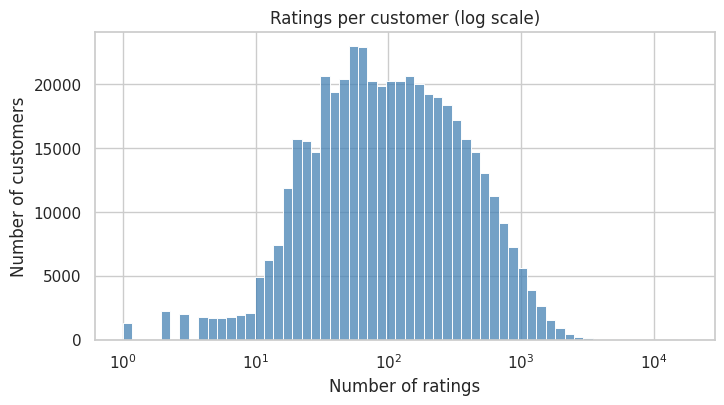

In [9]:
parts = [d.groupby('customer_id')['rating'].agg(['count', 'sum']) for d in dfs.values()]
cust_stats = pd.concat(parts).astype('int64').groupby(level=0).sum()
cust_stats['mean'] = cust_stats['sum'] / cust_stats['count']

# correctness tests
print('customers:', f"{len(cust_stats):,}")
print('total ratings:', f"{int(cust_stats['count'].sum()):,}")
print('overall mean:', round(cust_stats['sum'].sum() / cust_stats['count'].sum(), 4))

print(cust_stats['count'].describe(percentiles=[.1, .25, .5, .75, .9, .99]))
print(cust_stats['mean'].describe())

# chart: ratings per customer
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(cust_stats['count'], bins=60, log_scale=True, ax=ax, color='steelblue')
ax.set_title('Ratings per customer (log scale)')
ax.set_xlabel('Number of ratings')
ax.set_ylabel('Number of customers')
plt.show()

**Findings (4.3):**
- 480,189 customers; median 96 ratings, mean 209, max 17,653. A quarter of customers have fewer than 40 ratings (cold-start risk).
- Customer average ratings range widely (middle half: 3.38 to 3.98, std 0.473), so customers differ in generosity.
- Average of customer means (3.6741) is above the overall mean (3.6043): heavier raters tend to rate lower.
- Decision: baseline includes a customer bias term, with shrinkage for customers who have few ratings.

### 4.4 Ratings Over Time

**Question:** Is the average rating stable between 1999 and 2005? How does rating volume change?

**Approach:** Group by month inside each table (`count` and `sum`), add across the four tables, then `mean = sum / count`. Months with very few ratings are noisy, so read each average together with its count.

**Why it matters:** If the average drifts over time, the model needs time information.

**Correctness test:** total count = 100,480,507 and weighted mean = 3.6043.

total ratings: 100,480,507
overall mean: 3.6043
months: 74
         count   mean
date                 
1999      2178 3.3370
2000    924443 3.3652
2001   1769031 3.3907
2002   4342871 3.3818
2003   9985337 3.4063
2004  30206574 3.5950
2005  53250073 3.6761


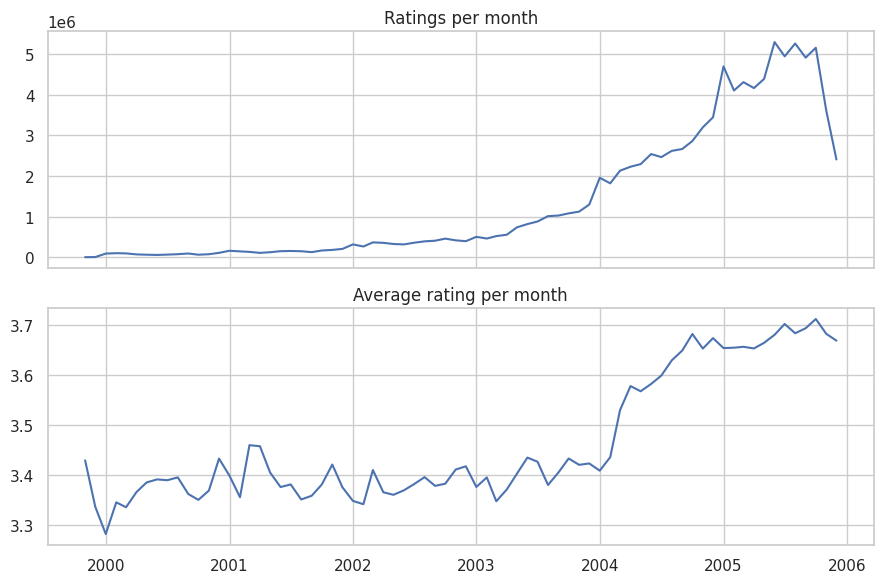

In [10]:
def month_stats(d):
    ym = d['date'].dt.year * 100 + d['date'].dt.month       
    return d['rating'].groupby(ym).agg(['count', 'sum'])

time_stats = pd.concat([month_stats(d) for d in dfs.values()]).groupby(level=0).sum()
time_stats['mean'] = time_stats['sum'] / time_stats['count']
time_stats.index = pd.to_datetime(time_stats.index.astype(str), format='%Y%m')

# correctness tests
print('total ratings:', f"{int(time_stats['count'].sum()):,}")
print('overall mean:', round(time_stats['sum'].sum() / time_stats['count'].sum(), 4))
print('months:', len(time_stats))

# text table by year (easy to paste)
yearly = time_stats.groupby(time_stats.index.year)[['count', 'sum']].sum()
yearly['mean'] = yearly['sum'] / yearly['count']
print(yearly[['count', 'mean']])

# charts
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(time_stats.index, time_stats['count'])
axes[0].set_title('Ratings per month')
axes[1].plot(time_stats.index, time_stats['mean'])
axes[1].set_title('Average rating per month')
plt.tight_layout()
plt.show()

**Findings (4.4):**
- Rating volume explodes over time: 2004 and 2005 hold about 83% of all ratings (2005 alone 53%).
- Yearly mean is roughly flat from 2000 to 2003 (3.37 to 3.41), then jumps to 3.595 in 2004 and 3.676 in 2005.
- The cause cannot be determined from this table (more generous users, a different mix of users or movies, or a change in how ratings were collected).
- The year-to-year differences explain under 1% of rating variance, far less than movie and customer effects.
- Decisions: leave time out of the first baseline, add it later as a measured upgrade, and validate with a time-based split (hold out the most recent months).
- The user-movie grid is only about 1.2% filled (100.5M of about 8.53B possible pairs).

### 4.5 Best and Worst Movies

**Question:** Which movies are rated highest and lowest, and does the result make sense?

**Approach:** Join movie titles onto the per-movie statistics. First show the top 5 by average with no filter (to demonstrate the small-sample problem), then require at least 10,000 ratings so averages are reliable (uncertainty about ±0.01).

**Why it matters:** Sanity check that movie IDs map to the right titles, and a demonstration of why shrinkage and minimum-count filters are needed.

In [12]:
pd.set_option('display.max_colwidth', 60)

# load titles (split on the first two commas only, titles can contain commas)
rows = []
with open(BASE + 'movie_titles.csv', 'r', encoding='latin-1') as f:
    for line in f:
        movie_id, year, title = line.strip().split(',', 2)
        rows.append((int(movie_id), year, title))

titles = pd.DataFrame(rows, columns=['movie_id', 'year', 'title']).set_index('movie_id')
titles['year'] = pd.to_numeric(titles['year'], errors='coerce').astype('Int16')
print('titles:', titles.shape)

named = movie_stats.join(titles)

print('\nTOP 5 BY MEAN, NO FILTER (the problem):')
print(named.sort_values('mean', ascending=False).head(5)[['title', 'count', 'mean']])

popular = named[named['count'] >= 10_000]
print('\nmovies with >= 10,000 ratings:', len(popular))

print('\nTOP 10 (>= 10,000 ratings):')
print(popular.sort_values('mean', ascending=False).head(10)[['title', 'count', 'mean']])

print('\nBOTTOM 10 (>= 10,000 ratings):')
print(popular.sort_values('mean').head(10)[['title', 'count', 'mean']])

titles: (17770, 2)

TOP 5 BY MEAN, NO FILTER (the problem):
                                                                title  count  \
movie_id                                                                       
14961     Lord of the Rings: The Return of the King: Extended Edition  73335   
7230      The Lord of the Rings: The Fellowship of the Ring: Exten...  73422   
7057              Lord of the Rings: The Two Towers: Extended Edition  74912   
3456                                                   Lost: Season 1   7249   
9864                                   Battlestar Galactica: Season 1   1747   

           mean  
movie_id         
14961    4.7233  
7230     4.7166  
7057     4.7026  
3456     4.6710  
9864     4.6388  

movies with >= 10,000 ratings: 2042

TOP 10 (>= 10,000 ratings):
                                                                title   count  \
movie_id                                                                        
14961     Lord of the Rin

**Findings (4.4):**
- Rating volume explodes over time: 2004 and 2005 hold about 83% of all ratings (2005 alone 53%).
- Yearly mean is roughly flat from 2000 to 2003 (3.37 to 3.41), then jumps to 3.595 in 2004 and 3.676 in 2005.
- The cause cannot be determined from this table (more generous users, a different mix of users or movies, or a change in how ratings were collected).
- The year-to-year differences explain under 1% of rating variance, far less than movie and customer effects.
- Decisions: leave time out of the first baseline, add it later as a measured upgrade, and validate with a time-based split (hold out the most recent months).
- The user-movie grid is only about 1.2% filled (100.5M of about 8.53B possible pairs).

### 4.5 Best and Worst Movies

**Question:** Which movies are rated highest and lowest, and does the result make sense?

**Approach:** Join movie titles onto the per-movie statistics. First show the top 5 by average with no filter (to demonstrate the small-sample problem), then require at least 10,000 ratings so averages are reliable (uncertainty about ±0.01).

**Why it matters:** Sanity check that movie IDs map to the right titles, and a demonstration of why shrinkage and minimum-count filters are needed.

In [13]:
pd.set_option('display.max_colwidth', 60)

# load titles (split on the first two commas only, titles can contain commas)
rows = []
with open(BASE + 'movie_titles.csv', 'r', encoding='latin-1') as f:
    for line in f:
        movie_id, year, title = line.strip().split(',', 2)
        rows.append((int(movie_id), year, title))

titles = pd.DataFrame(rows, columns=['movie_id', 'year', 'title']).set_index('movie_id')
titles['year'] = pd.to_numeric(titles['year'], errors='coerce').astype('Int16')
print('titles:', titles.shape)

named = movie_stats.join(titles)

print('\nTOP 5 BY MEAN, NO FILTER (the problem):')
print(named.sort_values('mean', ascending=False).head(5)[['title', 'count', 'mean']])

popular = named[named['count'] >= 10_000]
print('\nmovies with >= 10,000 ratings:', len(popular))

print('\nTOP 10 (>= 10,000 ratings):')
print(popular.sort_values('mean', ascending=False).head(10)[['title', 'count', 'mean']])

print('\nBOTTOM 10 (>= 10,000 ratings):')
print(popular.sort_values('mean').head(10)[['title', 'count', 'mean']])

titles: (17770, 2)

TOP 5 BY MEAN, NO FILTER (the problem):
                                                                title  count  \
movie_id                                                                       
14961     Lord of the Rings: The Return of the King: Extended Edition  73335   
7230      The Lord of the Rings: The Fellowship of the Ring: Exten...  73422   
7057              Lord of the Rings: The Two Towers: Extended Edition  74912   
3456                                                   Lost: Season 1   7249   
9864                                   Battlestar Galactica: Season 1   1747   

           mean  
movie_id         
14961    4.7233  
7230     4.7166  
7057     4.7026  
3456     4.6710  
9864     4.6388  

movies with >= 10,000 ratings: 2042

TOP 10 (>= 10,000 ratings):
                                                                title   count  \
movie_id                                                                        
14961     Lord of the Rin

**Findings (4.5):**
- Movie IDs map correctly to titles (sanity check passed): top titles are the Lord of the Rings extended editions (4.70 to 4.72), The Shawshank Redemption, The Empire Strikes Back and seasons of The Simpsons and The Sopranos.
- Among the 2,042 movies with 10,000+ ratings, averages range from 2.41 to 4.72, so the movie effect is large.
- The unfiltered top 5 were already high-volume titles, so thin movies did not reach the top of the ranking. Whether small samples distort averages is tested separately in 4.6.
- Highly rated titles (extended editions, TV seasons) probably reflect devoted-fan audiences (hypothesis).
- Different versions of the same film appear as separate movies.

### 4.6 Do Thin Movies Have Less Reliable Averages?

**Claim:** Movies with few ratings have more spread-out averages than movies with many ratings (small samples are noisy).

**Test:** Bucket movies by number of ratings and compare the spread (std) of movie averages within each bucket.

**Interpretation:** If the spread shrinks as counts grow, shrinkage toward the global mean is justified. Part of the spread among thin movies may be real quality differences, so the validation score will make the final call.

In [14]:
bins = [0, 100, 300, 1_000, 3_000, 10_000, 30_000, 300_000]
named['bucket'] = pd.cut(named['count'], bins=bins)

funnel = named.groupby('bucket', observed=True)['mean'].agg(['size', 'mean', 'std', 'min', 'max'])
print(funnel)

print('\n8 THINNEST MOVIES:')
print(named.sort_values('count').head(8)[['title', 'count', 'mean']])

                 size   mean    std    min    max
bucket                                           
(0, 100]         1010 2.8279 0.5474 1.4222 4.6000
(100, 300]       5492 2.9483 0.4951 1.2879 4.5864
(300, 1000]      4143 3.2513 0.4678 1.5039 4.5389
(1000, 3000]     2943 3.4231 0.4479 1.7626 4.6388
(3000, 10000]    2140 3.4745 0.4255 1.9460 4.6710
(10000, 30000]   1171 3.5435 0.3771 2.4052 4.5426
(30000, 300000]   871 3.6588 0.3479 2.6016 4.7233

8 THINNEST MOVIES:
                                                       title  count   mean
movie_id                                                                  
13755                                   Mobsters and Mormons      3 4.0000
11148     The Land Before Time IV: Journey Through the Mists      5 4.2000
11344                                             Hockey Mom     10 2.4000
6256                             Larryboy and the Rumor Weed     10 2.4000
4806                                  Dune: Extended Edition     13 3.7692
8146 

**Findings (4.6):**
- The spread (std) of movie averages falls as ratings grow: 0.547 (up to 100 ratings) to 0.348 (over 30,000), a ratio of about 1.6.
- A rough calculation shows sampling noise explains only a small part of the spread in thin buckets (about 0.01 of the 0.25 to 0.30 variance for 100 ratings). Most of it is real variation between movies.
- Popularity and rating are related: the mean of movie averages rises from 2.83 (up to 100 ratings) to 3.66 (over 30,000).
- Decisions: tune shrinkage strength on validation (no shrinkage is a candidate), expect shrinkage to matter more for customers than for movies, and let matrix factorization capture the popularity effect.

## 5. Baseline Models

### 5.1 Train / Validation Split

**Goal:** Measure how well a model predicts ratings it has never seen.

**Choice:** Time-based split. Validation = all ratings on or after 2005-12-01 (the most recent month). Training = everything before. This mimics predicting the future (the original competition's test data was also later than the training data), whereas a random split would leak future behaviour into training.

**Rules:**
1. All model statistics (means, biases) are computed from training rows only. The EDA tables (`movie_stats`, `cust_stats`, `time_stats`) used all data and must not be reused for modeling.
2. Settings such as shrinkage strength are tuned on validation.

**Metric:** RMSE (lower is better).

In [15]:
CUTOFF = pd.Timestamp('2005-12-01')     # on or after this date = validation

val = pd.concat([d[d['date'] >= CUTOFF] for d in dfs.values()], ignore_index=True)

n_total = sum(len(d) for d in dfs.values())
n_val = len(val)
n_train = n_total - n_val

print('validation rows:', f"{n_val:,}", f"({n_val / n_total:.2%} of all ratings)")
print('training rows:  ', f"{n_train:,}")
print('validation dates:', val['date'].min().date(), 'to', val['date'].max().date())

# means (training mean = (total sum - validation sum) / training rows)
total_sum = int((rating_counts.index * rating_counts).sum())
train_mean = (total_sum - int(val['rating'].sum())) / n_train
print('training mean rating:  ', round(train_mean, 4))
print('validation mean rating:', round(val['rating'].mean(), 4))

validation rows: 2,405,578 (2.39% of all ratings)
training rows:   98,074,929
validation dates: 2005-12-01 to 2005-12-31
training mean rating:   3.6027
validation mean rating: 3.668


**Findings (5.1):**
- Validation = December 2005: 2,405,578 rows (2.39%). Training = 98,074,929 rows.
- Training mean 3.6027 vs validation mean 3.668: the upward drift from section 4.4 is visible in the split.
- All model statistics from here on are computed from training rows only.

### 5.2 Baseline 1: Global Mean

**Idea:** Predict the training mean (3.6027) for every rating. This is the yardstick every later model must beat.

**Metric:** RMSE = square root of the mean squared error ("typical miss in stars", with large misses penalised more).

**Setup:** A reusable `rmse()` function and a `results` dictionary that collects every model's validation score.

**Extra checks:** RMSE for several constants (it should be lowest at the mean), and the "cheating" constant using the validation mean, which measures the cost of the upward drift.

In [16]:
def rmse(pred, truth):
    return float(np.sqrt(np.mean((truth - pred) ** 2)))

y_val = val['rating'].to_numpy().astype('float64')

results = {}                                  # scoreboard for all models
results['1. global mean'] = rmse(train_mean, y_val)
print('Global mean RMSE:', round(results['1. global mean'], 4))

# what if we knew the validation mean? (cheating, for comparison only)
print('Cheating constant RMSE:', round(rmse(y_val.mean(), y_val), 4))

# RMSE for different constant guesses
print('\nconstant -> RMSE')
for c in [1, 2, 3, round(train_mean, 4), 4, 5]:
    print(f'{c:>8} -> {rmse(c, y_val):.4f}')

Global mean RMSE: 1.0802
Cheating constant RMSE: 1.0782

constant -> RMSE
       1 -> 2.8777
       2 -> 1.9862
       3 -> 1.2684
  3.6027 -> 1.0802
       4 -> 1.1282
       5 -> 1.7137


**Findings (5.2):**
- Predicting the training mean (3.6027) for every rating gives validation RMSE **1.0802**: a typical miss of about 1.08 stars.
- Knowing the validation mean in advance would give 1.0782, so the upward drift costs only about 0.002 RMSE.
- RMSE for a constant guess is a parabola with its minimum at the mean, as expected (RMSE² = variance + squared bias).
- This is the baseline every later model must beat.

### 5.3 Baseline 2: Global Mean + Movie Effect

**Idea:** Each movie is liked more or less than average. Predict `global mean + movie effect`.

**Movie effect:** `sum of (rating - global mean) / (n + k)`, computed from training rows only. `k` is a shrinkage strength: it pulls movies with few ratings toward zero effect (k = 0 means no shrinkage).

**Tuning:** Try k = 0, 1, 5, 10, 25, 50, 100 and keep the best on validation. Movies absent from the training data get effect 0.

**Caveat:** Tuning and reporting on the same validation set is slightly optimistic; the effect is small here (7 candidates, 2.4M ratings).

In [17]:
# 1. per-movie count and sum, from TRAINING rows only
def train_movie_stats(d):
    tr = d[d['date'] < CUTOFF]
    return tr['rating'].groupby(tr['movie_id']).agg(['count', 'sum'])

movie_train = pd.concat([train_movie_stats(d) for d in dfs.values()]).groupby(level=0).sum()
n_i = movie_train['count']
s_i = movie_train['sum'] - n_i * train_mean          # sum of residuals per movie

# 2. line them up with validation rows
s_v = val['movie_id'].map(s_i).fillna(0).to_numpy()
n_v = val['movie_id'].map(n_i).fillna(0).to_numpy()
print('validation rows from movies with no training ratings:', int((n_v == 0).sum()))

# 3. try different shrinkage strengths
scores = {}
for k in [0, 1, 5, 10, 25, 50, 100]:
    den = n_v + k
    b = np.divide(s_v, den, out=np.zeros_like(s_v), where=den > 0)
    scores[k] = rmse(train_mean + b, y_val)
    print(f'k = {k:>3} -> RMSE {scores[k]:.4f}')

best_k = min(scores, key=scores.get)
results[f'2. + movie effect (k={best_k})'] = scores[best_k]
print('\nbest k:', best_k, '| RMSE:', round(scores[best_k], 4),
      '| improvement vs global mean:', f"{1 - scores[best_k] / results['1. global mean']:.2%}")

validation rows from movies with no training ratings: 23
k =   0 -> RMSE 1.0172
k =   1 -> RMSE 1.0172
k =   5 -> RMSE 1.0171
k =  10 -> RMSE 1.0171
k =  25 -> RMSE 1.0170
k =  50 -> RMSE 1.0170
k = 100 -> RMSE 1.0172

best k: 25 | RMSE: 1.017 | improvement vs global mean: 5.85%


**Findings (5.3):**
- Global mean + movie effect: validation RMSE **1.0170** (5.85% better than 1.0802, about 11.4% of squared error removed).
- Only 23 validation rows come from movies with no training ratings.
- Shrinkage strength barely matters for movies: RMSE ranges from 1.0170 to 1.0172 across k = 0 to 100. Chose k = 25, the middle of a flat optimum.

### 5.4 Baseline 3: Global Mean + Movie Effect + Customer Effect

**Idea:** Some customers rate more generously than others. Predict `global mean + movie effect + customer effect`.

**Key step:** The customer effect is measured on the residual `rating - global mean - movie effect`, so that a customer who happens to watch well-loved movies is not mistaken for a generous one.

**Customer effect:** `sum of residuals / (n + lambda)`, from training rows only. `lambda` is a shrinkage strength tuned on validation (0 is included). Customers absent from training get effect 0.

**Note:** Movie effects use k = 25 (chosen in 5.3). A fully joint estimate of both effects is left for the matrix-factorization model.

In [20]:
# 1. movie effects with the chosen k (recomputed, not the leftover variable b)
b_movie = s_i / (n_i + best_k)

# 2. residuals per training rating, then per-customer count and sum
def train_customer_stats(d):
    tr = d[d['date'] < CUTOFF]
    resid = tr['rating'].to_numpy() - train_mean - tr['movie_id'].map(b_movie).to_numpy()
    return pd.Series(resid).groupby(tr['customer_id'].to_numpy()).agg(['count', 'sum'])

cust_train = pd.concat([train_customer_stats(d) for d in dfs.values()]).groupby(level=0).sum()
n_u = cust_train['count']
s_u = cust_train['sum']

# 3. line up with validation rows
nu_v = val['customer_id'].map(n_u).fillna(0).to_numpy()
su_v = val['customer_id'].map(s_u).fillna(0).to_numpy()
bm_v = np.divide(s_v, n_v + best_k, out=np.zeros_like(s_v), where=(n_v + best_k) > 0)
print('validation rows from customers with no training ratings:', int((nu_v == 0).sum()))

# 4. try different lambda values
scores_u = {}
for lam in [0, 1, 5, 10, 25, 50, 100]:
    den = nu_v + lam
    bu = np.divide(su_v, den, out=np.zeros_like(su_v), where=den > 0)
    scores_u[lam] = rmse(train_mean + bm_v + bu, y_val)
    print(f'lambda = {lam:>3} -> RMSE {scores_u[lam]:.4f}')

best_lam = min(scores_u, key=scores_u.get)
results[f'3. + customer effect (lambda={best_lam})'] = scores_u[best_lam]
print('\nbest lambda:', best_lam, '| RMSE:', round(scores_u[best_lam], 4))
print('improvement vs movie-only:', f"{1 - scores_u[best_lam] / results[f'2. + movie effect (k={best_k})']:.2%}")
print('improvement vs global mean:', f"{1 - scores_u[best_lam] / results['1. global mean']:.2%}")

validation rows from customers with no training ratings: 155074
lambda =   0 -> RMSE 0.9862
lambda =   1 -> RMSE 0.9693
lambda =   5 -> RMSE 0.9599
lambda =  10 -> RMSE 0.9577
lambda =  25 -> RMSE 0.9565
lambda =  50 -> RMSE 0.9572
lambda = 100 -> RMSE 0.9602

best lambda: 25 | RMSE: 0.9565
improvement vs movie-only: 5.95%
improvement vs global mean: 11.46%


**Findings (5.4):**
- Global mean + movie effect + customer effect: validation RMSE **0.9565** (5.95% better than movie-only, 11.46% better than the global mean; about 21.6% of squared error removed in total).
- Shrinkage matters a lot for customers: lambda = 0 gives 0.9862 and lambda = 25 gives 0.9565 (for movies the same tuning changed RMSE by 0.0002). Customers have far less data each than movies.
- lambda = 25 implies a true spread of customer generosity of about 0.2 stars (rough estimate), much smaller than the raw 0.47 seen in 4.3, which was inflated by noise and by differing movie mix.
- 155,074 validation rows (6.45%) come from customers with no training ratings; they receive only global mean + movie effect (cold-start problem).

### 5.5 Where Does the Remaining Error Come From

**Question:** How does validation RMSE vary with how much we know about the customer (their number of training ratings)?

**Approach:** Rebuild the best predictions from 5.4 and group validation rows by the customer's training rating count (0 = unseen customer). Report each group's share of rows and its RMSE.

**Why it matters:** It shows how much of the error is cold-start (unseen or very light customers) versus the customer-movie interaction that biases cannot capture, and therefore what the next model needs to fix.

In [25]:
den = nu_v + best_lam
bu = np.divide(su_v, den, out=np.zeros_like(su_v), where=den > 0)
best_pred = train_mean + bm_v + bu
err2 = (y_val - best_pred) ** 2
print('check, overall RMSE:', round(float(np.sqrt(err2.mean())), 4))

bucket = pd.cut(nu_v, bins=[-1, 0, 20, 50, 100, 300, 1000, 100_000])
by_bucket = (pd.DataFrame({'bucket': bucket, 'err2': err2})
             .groupby('bucket', observed=True)['err2'].agg(['size', 'mean']))
by_bucket['share_of_rows'] = by_bucket['size'] / by_bucket['size'].sum()
by_bucket['rmse'] = np.sqrt(by_bucket['mean'])
print(by_bucket[['size', 'share_of_rows', 'rmse']])

check, overall RMSE: 0.9565
                  size  share_of_rows   rmse
bucket                                      
(-1, 0]         155074         0.0645 1.1094
(0, 20]         282601         0.1175 1.0793
(20, 50]        142001         0.0590 0.9884
(50, 100]       238513         0.0991 0.9747
(100, 300]      626141         0.2603 0.9210
(300, 1000]     753165         0.3131 0.9011
(1000, 100000]  208083         0.0865 0.9110


**Findings (5.5):**
- Error falls as we know more about the customer: RMSE 1.109 for unseen customers (6.5% of rows) and 1.079 for customers with 1 to 20 training ratings (11.8%), down to about 0.90 for customers with 300+ ratings.
- Unseen plus very light customers are 18.2% of rows but 23.6% of squared error; about 76% of the error comes from customers with 20+ ratings.
- Fixing cold-start perfectly (to about 0.95 RMSE) would give at most about 0.028 RMSE, so the larger opportunity is the customer-movie interaction, which biases cannot capture.
- The heaviest raters (1000+ ratings) are slightly harder to predict (0.911) than the 300 to 1000 group (0.901).
- Backlog: cold-start handling, time effect.

## 6. Matrix Factorization

**Idea:** Give each customer and each movie a short list of numbers (latent factors, "taste dials") learned from the data. Prediction = global mean + movie effect + customer effect + dot product of the customer's and movie's factor lists.

**Why:** Biases cannot express taste ("likes action, dislikes romance"). 76% of the remaining error (section 5.5) is this customer-movie interaction.

**Implementation:** PyTorch embedding tables trained with mini-batches (fast enough for 98M ratings). Develop and debug on a sample first, then train on all training rows.

**Evaluation:** Validation RMSE (December 2005), compared against the 0.9565 baseline.

### 6.1 Environment Check

**Goal:** Know what hardware is available (GPU, RAM, CPU cores) before designing the training loop.

In [27]:
print('torch version:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0),
          '|', round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), 'GB')
print('CPU cores:', os.cpu_count())
mem = psutil.virtual_memory()
print('RAM total GB:', round(mem.total / 1e9, 1), '| available GB:', round(mem.available / 1e9, 1))

torch version: 2.11.0+cpu
GPU available: False
CPU cores: 4
RAM total GB: 33.7 | available GB: 30.3


### 6.2 Prepare Data for Matrix Factorization

**Goal:** Turn each rating into (customer position, movie position, residual) arrays for fast training.

**Residual:** `rating - global mean - movie effect - customer effect`, with effects estimated from training rows only (k = 25, lambda = 25). The factors will learn what the biases cannot explain.

**Indexing:** Customers are mapped to compact positions 0..480,188 with `np.searchsorted` on the sorted ID list from 4.3; movie position = `movie_id - 1`.

**Correctness test:** With all factors at zero, validation RMSE must equal the baseline 0.9565.

**Checkpoint:** Arrays are saved to `/kaggle/working/` so a session restart does not lose them.

In [28]:
# --- lookup tables: effects by position (training-only effects) ---
cust_ids = cust_stats.index.to_numpy()                       # sorted IDs of all 480,189 customers
print('customers:', len(cust_ids), '| sorted:', bool((np.diff(cust_ids) > 0).all()))

bm_table = b_movie.reindex(np.arange(1, 17771)).fillna(0).to_numpy().astype('float32')   # position = movie_id - 1
bu_table = (s_u / (n_u + best_lam)).reindex(cust_ids).fillna(0).to_numpy().astype('float32')  # position = compact customer index

# --- build arrays for a set of rows ---
def build_arrays(sel):
    u = np.searchsorted(cust_ids, sel['customer_id'].to_numpy()).astype('int32')
    m = sel['movie_id'].to_numpy().astype('int32') - 1
    res = sel['rating'].to_numpy().astype('float32') - np.float32(train_mean) - bm_table[m] - bu_table[u]
    return u, m, res.astype('float32')

parts = [build_arrays(d[d['date'] < CUTOFF]) for d in dfs.values()]
tr_u = np.concatenate([p[0] for p in parts])
tr_m = np.concatenate([p[1] for p in parts])
tr_res = np.concatenate([p[2] for p in parts])
del parts
gc.collect()

va_u, va_m, va_res = build_arrays(val)

# --- checks ---
print('training rows:  ', f"{len(tr_u):,}")
print('validation rows:', f"{len(va_u):,}")
print('validation RMSE of residuals (must be 0.9565):', round(float(np.sqrt(np.mean(va_res ** 2, dtype='float64'))), 4))
print('training RMSE of residuals (in-sample):', round(float(np.sqrt(np.mean(tr_res ** 2, dtype='float64'))), 4))
print('training residual mean:', round(float(tr_res.mean(dtype='float64')), 5))

# --- checkpoint to disk ---
OUT = '/kaggle/working/'
for name, arr in [('tr_u', tr_u), ('tr_m', tr_m), ('tr_res', tr_res), ('va_u', va_u), ('va_m', va_m),
                  ('va_res', va_res), ('cust_ids', cust_ids), ('bm_table', bm_table), ('bu_table', bu_table)]:
    np.save(OUT + name + '.npy', arr)
print('saved to', OUT)

customers: 480189 | sorted: True
training rows:   98,074,929
validation rows: 2,405,578
validation RMSE of residuals (must be 0.9565): 0.9565
training RMSE of residuals (in-sample): 0.9206
training residual mean: 0.0039
saved to /kaggle/working/


**Findings (6.2):**
- Prepared 98,074,929 training and 2,405,578 validation rows as (customer position, movie position, residual) arrays.
- Correctness test passed: validation RMSE of the residuals is 0.9565, the same as the baseline.
- In-sample training residual RMSE is 0.9206, lower than validation (0.9565) because effects were fitted on training rows and validation contains unseen and light customers. Models are judged on validation only.
- Arrays were saved to /kaggle/working.

### 6.3 The Model

**Structure:** Two embedding tables ("lookup sheets"): one row of d = 20 numbers per customer, one per movie. Prediction for a (customer, movie) pair = dot product of the two rows. This predicts the residual left over after the baseline (global mean + movie effect + customer effect).

**Settings:** d = 20 factors; initial values drawn from a normal distribution with std 0.1 (zeros would never separate).

**Tests:**
1. With all factors set to zero, validation RMSE must equal the baseline (0.9565), which also verifies `evaluate()`.
2. A random start should score about 0.9575 (RMSE² = 0.9149 + 20 x 0.1² x 0.1²).

In [29]:
torch.set_num_threads(os.cpu_count())

class MF(torch.nn.Module):
    """Prediction = dot product of a customer's factor list and a movie's factor list."""
    def __init__(self, n_users, n_items, d, init_std=0.1):
        super().__init__()
        self.U = torch.nn.Embedding(n_users, d)      # one row of d numbers per customer
        self.V = torch.nn.Embedding(n_items, d)      # one row of d numbers per movie
        torch.nn.init.normal_(self.U.weight, std=init_std)
        torch.nn.init.normal_(self.V.weight, std=init_std)

    def forward(self, u, m):
        return (self.U(u) * self.V(m)).sum(dim=1)    # multiply matching dials, then add up

def evaluate(model, u, m, res, batch=500_000):
    """RMSE of the model's predictions against the residuals, computed in chunks."""
    model.eval()
    se = 0.0
    with torch.no_grad():
        for i in range(0, len(u), batch):
            ub = torch.from_numpy(u[i:i + batch]).long()
            mb = torch.from_numpy(m[i:i + batch]).long()
            rb = torch.from_numpy(res[i:i + batch])
            err = rb - model(ub, mb)
            se += float((err.double() ** 2).sum())
    return (se / len(u)) ** 0.5

torch.manual_seed(0)
model = MF(n_users=len(cust_ids), n_items=17770, d=20)
print('parameters:', f"{sum(p.numel() for p in model.parameters()):,}")
print('random start, validation RMSE:', round(evaluate(model, va_u, va_m, va_res), 4))

with torch.no_grad():
    model.U.weight.zero_()
    model.V.weight.zero_()
print('all-zero factors, validation RMSE (must be 0.9565):', round(evaluate(model, va_u, va_m, va_res), 4))

parameters: 9,959,180
random start, validation RMSE: 0.9575
all-zero factors, validation RMSE (must be 0.9565): 0.9565


**Findings (6.3):**
- Model: two embedding tables (480,189 customers and 17,770 movies, 20 factors each), 9,959,180 parameters.
- All-zero factors reproduce the baseline (validation RMSE 0.9565), verifying `evaluate()`.
- A random start (std 0.1) scores 0.9575, matching the prediction sqrt(0.9149 + 0.002). Training must beat both numbers.

### 6.4 Training on a Development Sample

**Sample:** 10% of customers, with all their ratings (about 9.8M training rows), and the validation rows of the same customers. Sampling by customer keeps each customer's full history, which is what taste learning needs.

**Training loop:** mini-batches of 50,000 ratings; for each batch predict the residual, compute the loss, and nudge the factors with Adam (learning rate 0.01).

**Loss:** mean squared error + `reg` x (squared size of the customer and movie factors used). `reg` is a leash against memorizing; first guess 0.02, tuned next.

**Monitoring:** training and validation RMSE per epoch (validation is compared with the baseline on the same customers), plus seconds per epoch to extrapolate to the full 98M rows.

In [32]:
rng = np.random.default_rng(0)
keep = rng.random(len(cust_ids)) < 0.10          # True for customers in the sample

tr_mask = keep[tr_u]
va_mask = keep[va_u]
dev_tu, dev_tm, dev_tr = tr_u[tr_mask], tr_m[tr_mask], tr_res[tr_mask]
dev_vu, dev_vm, dev_vr = va_u[va_mask], va_m[va_mask], va_res[va_mask]

print('sample customers:', int(keep.sum()))
print('sample training rows:  ', f"{len(dev_tu):,}")
print('sample validation rows:', f"{len(dev_vu):,}")
print('baseline RMSE on this sample (no factors):', round(float(np.sqrt(np.mean(dev_vr ** 2, dtype='float64'))), 4))

# ---- 2. the training loop ----
def fit(model, tu, tm, tr, vu, vm, vr, epochs=6, batch=50_000, lr=0.01, reg=0.02, seed=0):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = np.random.default_rng(seed)
    n = len(tu)
    for ep in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        perm = g.permutation(n)                       # shuffle the order of the ratings
        run_se, run_n = 0.0, 0
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            ub = torch.from_numpy(tu[idx]).long()
            mb = torch.from_numpy(tm[idx]).long()
            rb = torch.from_numpy(tr[idx])
            Ub, Vb = model.U(ub), model.V(mb)         # look up the dials
            err = rb - (Ub * Vb).sum(dim=1)           # prediction error
            loss = (err ** 2).mean() + reg * (Ub.pow(2).sum(dim=1) + Vb.pow(2).sum(dim=1)).mean()
            opt.zero_grad()
            loss.backward()                           # which way to nudge each dial
            opt.step()                                # nudge
            run_se += float((err.detach().double() ** 2).sum())
            run_n += len(idx)
        val = evaluate(model, vu, vm, vr)
        print(f'epoch {ep}: train RMSE {np.sqrt(run_se / run_n):.4f} | '
              f'val RMSE {val:.4f} | {time.time() - t0:.0f} s')
    return model


torch.manual_seed(0)
dev_model = MF(n_users=len(cust_ids), n_items=17770, d=20)
dev_model = fit(dev_model, dev_tu, dev_tm, dev_tr, dev_vu, dev_vm, dev_vr)

sample customers: 48167
sample training rows:   9,933,194
sample validation rows: 256,197
baseline RMSE on this sample (no factors): 0.9578
epoch 1: train RMSE 0.9035 | val RMSE 0.9395 | 24 s
epoch 2: train RMSE 0.8541 | val RMSE 0.9313 | 24 s
epoch 3: train RMSE 0.8228 | val RMSE 0.9318 | 24 s
epoch 4: train RMSE 0.8061 | val RMSE 0.9353 | 21 s
epoch 5: train RMSE 0.7967 | val RMSE 0.9368 | 23 s
epoch 6: train RMSE 0.7908 | val RMSE 0.9391 | 21 s
